In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set plotting styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [11]:
# Load your dataset (Replace 'dataset.csv' with your actual file path)
df = pd.read_csv("dataset.csv")

# 1. Fill missing numeric values with median, and categorical with mode
numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
    
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(f"Dataset loaded successfully with shape: {df.shape}")

Dataset loaded successfully with shape: (100000, 25)


In [12]:
# Create emission intensity proxy metrics to help the model learn efficiency trends
df['emissions_per_revenue'] = df['annual_carbon_emissions_tco2e'] / (df['annual_revenue'] + 1)
df['energy_intensity'] = (df['electricity_consumption_mwh'] + df['natural_gas_consumption_mmbtu']) / (df['annual_output_volume'] + 1)

# Define features (X) and target variable (y)
X_features = [
    'year', 'industry_sector', 'region', 'employee_count', 'annual_revenue', 
    'annual_output_volume', 'electricity_consumption_mwh', 'natural_gas_consumption_mmbtu', 
    'diesel_consumption_liters', 'renewable_electricity_share_pct', 'fleet_size', 'waste_generated_tons'
]
y_target = 'annual_carbon_emissions_tco2e'

X = df[X_features]
y = df[y_target]

In [13]:
# 1. Chronological Time Split (Train on past years, test on the latest year)
latest_year = X['year'].max()
X_train, X_test = X[X['year'] < latest_year], X[X['year'] == latest_year]
y_train, y_test = y[X['year'] < latest_year], y[X['year'] == latest_year]

# 2. Define preprocessing for Categorical vs Numeric features
numeric_features = ['year', 'employee_count', 'annual_revenue', 'annual_output_volume', 
                    'electricity_consumption_mwh', 'natural_gas_consumption_mmbtu', 
                    'diesel_consumption_liters', 'renewable_electricity_share_pct', 'fleet_size', 'waste_generated_tons']
categorical_features = ['industry_sector', 'region']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# 3. Create the modeling pipeline using a Gradient Boosting Regressor
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, random_state=42))
])

# 4. Fit the pipeline
model_pipeline.fit(X_train, y_train)
print("Model pipeline trained successfully.")

Model pipeline trained successfully.


In [14]:
# Predict on validation data
y_pred = model_pipeline.predict(X_test)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"--- Emission Model Evaluation Metrics ---")
print(f"Mean Absolute Error: {mae:.2f} tCO2e")
print(f"Root Mean Squared Error: {rmse:.2f} tCO2e")
print(f"R² Prediction Accuracy Score: {r2:.4f}")

--- Emission Model Evaluation Metrics ---
Mean Absolute Error: 0.19 tCO2e
Root Mean Squared Error: 0.21 tCO2e
R² Prediction Accuracy Score: 0.9377


In [16]:
def calculate_carbon_tax_planning(predicted_emissions, tax_rate_per_ton=30.0, allowance_pct=0.20, penalty_base=5000):
    """
    Computes corporate tax planning outcomes using predicted emissions.
    allowance_pct represents the percentage of emissions that are tax-exempt.
    """
    # Calculate tax free baseline allowance
    allowance = predicted_emissions * allowance_pct
    
    # Taxable emissions cannot fall below zero
    taxable_emissions = np.maximum(0, predicted_emissions - allowance)
    
    # Core tax liability
    base_tax_liability = taxable_emissions * tax_rate_per_ton
    
    # Conditional penalty application if emissions hit critical thresholds
    penalty = np.where(predicted_emissions > 50000, penalty_base * 1.5, 0)
    
    total_liability = base_tax_liability + penalty
    
    return pd.DataFrame({
        'Predicted_Emissions_tCO2e': predicted_emissions,
        'Tax_Free_Allowance': allowance,
        'Taxable_Emissions': taxable_emissions,
        'Base_Tax_Liability': base_tax_liability,
        'Applied_Penalty': penalty,
        'Total_Financial_Liability': total_liability
    })

# Run corporate tax forecasting for the next year
financial_forecast = calculate_carbon_tax_planning(y_pred, tax_rate_per_ton=35.0, allowance_pct=0.15)
print("\n--- Financial Planning Sample Output for Next Financial Year ---")
print(financial_forecast.head())


--- Financial Planning Sample Output for Next Financial Year ---
   Predicted_Emissions_tCO2e  Tax_Free_Allowance  Taxable_Emissions  \
0                   1.911920            0.286788           1.625132   
1                   2.048370            0.307256           1.741115   
2                   2.232096            0.334814           1.897281   
3                   2.307237            0.346086           1.961151   
4                   2.478199            0.371730           2.106469   

   Base_Tax_Liability  Applied_Penalty  Total_Financial_Liability  
0           56.879608              0.0                  56.879608  
1           60.939018              0.0                  60.939018  
2           66.404843              0.0                  66.404843  
3           68.640300              0.0                  68.640300  
4           73.726419              0.0                  73.726419  


C:\Users\HX109WS\AppData\Local\Temp\ipykernel_31784\2733807293.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Tax Rate ($)', y='Total Corporate Tax Liability ($)', data=scenario_df, palette="viridis")


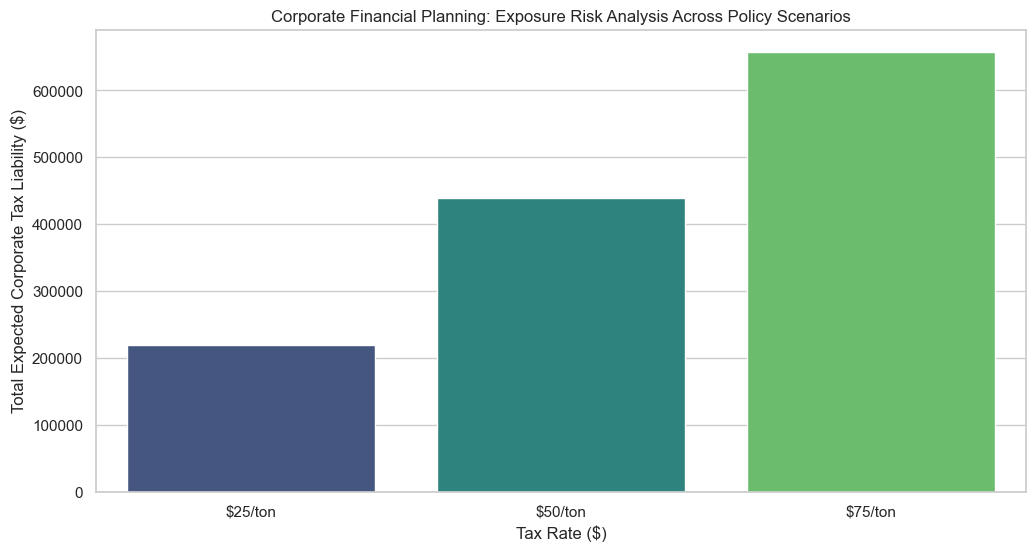

In [17]:
rates_to_test = [25, 50, 75]
scenario_results = []

for rate in rates_to_test:
    sim = calculate_carbon_tax_planning(y_pred, tax_rate_per_ton=rate)
    total_cost = sim['Total_Financial_Liability'].sum()
    scenario_results.append({'Tax Rate ($)': f"${rate}/ton", 'Total Corporate Tax Liability ($)': total_cost})

scenario_df = pd.DataFrame(scenario_results)

# Plotting the financial exposure
sns.barplot(x='Tax Rate ($)', y='Total Corporate Tax Liability ($)', data=scenario_df, palette="viridis")
plt.title("Corporate Financial Planning: Exposure Risk Analysis Across Policy Scenarios")
plt.ylabel("Total Expected Corporate Tax Liability ($)")
plt.show()

In [18]:
import pickle

# Define the deployment filename
model_filename = "carbon_tax_prediction_pipeline.pkl"

# Save the entire structured pipeline object to disk
with open(model_filename, 'wb') as file:
    pickle.dump(model_pipeline, file)

print(f"Success: Machine learning pipeline successfully serialized to {model_filename}")

Success: Machine learning pipeline successfully serialized to carbon_tax_prediction_pipeline.pkl


In [19]:
# 1. Simulating a clean runtime environment by loading the pkl file
with open(model_filename, 'rb') as file:
    loaded_pipeline = pickle.load(file)

# 2. Testing prediction capability using raw validation sample inputs
test_sample = X_test.iloc[[0]] 
sample_prediction = loaded_pipeline.predict(test_sample)

print("--- Verification Diagnostics ---")
print(f"File Status: Operational")
print(f"Pipeline Input Structure Requirements Met: True")
print(f"Sample Forecast Output: {sample_prediction[0]:.2f} tCO2e")

--- Verification Diagnostics ---
File Status: Operational
Pipeline Input Structure Requirements Met: True
Sample Forecast Output: 1.91 tCO2e


In [20]:
import pandas as pd
import pickle

# 1. Load the pipeline asset
with open("carbon_tax_prediction_pipeline.pkl", "rb") as file:
    loaded_pipeline = pickle.load(file)

# 2. Define the upcoming year's operational projections
upcoming_year_data = pd.DataFrame([{
    'year': 2027,
    'industry_sector': 'Manufacturing',
    'region': 'Europe',
    'employee_count': 520,
    'annual_revenue': 35000000,
    'annual_output_volume': 12.5,
    'electricity_consumption_mwh': 5500,
    'natural_gas_consumption_mmbtu': 45000,
    'diesel_consumption_liters': 12000,
    'renewable_electricity_share_pct': 25.0,
    'fleet_size': 45,
    'waste_generated_tons': 190
}])

# 3. Generate the forecast
predicted_tco2e = loaded_pipeline.predict(upcoming_year_data)[0]
print(f"Predicted Emissions for 2027: {predicted_tco2e:.2f} tCO2e")

Predicted Emissions for 2027: 8.39 tCO2e


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   organization_id                  100000 non-null  object 
 1   year                             100000 non-null  int64  
 2   industry_sector                  100000 non-null  object 
 3   region                           100000 non-null  object 
 4   employee_count                   100000 non-null  int64  
 5   annual_revenue                   100000 non-null  float64
 6   annual_output_volume             100000 non-null  float64
 7   electricity_consumption_mwh      100000 non-null  float64
 8   natural_gas_consumption_mmbtu    100000 non-null  float64
 9   diesel_consumption_liters        100000 non-null  float64
 10  renewable_electricity_share_pct  100000 non-null  float64
 11  fleet_size                       100000 non-null  int64  
 12  was